# Why is Garden less profitable? Stories coffee transactions
Business question: Garden branch seems to earn less gross margin than Harbour and Uptown. Is it **costs**, **prices**, or something else (product mix, order type, time of day)?

In [1]:
import pandas as pd, numpy as np, matplotlib
import matplotlib.pyplot as plt
pd.set_option('display.width',200); pd.set_option('display.max_columns',30)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
COL={'Garden':'#d95f02','Harbour':'#1b9e77','Uptown':'#7570b3'}
FIG='figures/'
raw=pd.read_csv('../data/stories_transactions.csv')
print(raw.shape)
raw.head()

(51177, 14)


,Transaction ID,Date,Time,Branch,Customer ID,Order Type,Product,Category,Quantity,Unit Price (USD),Discount Rate,Unit Cost (USD),Line Revenue (USD),Line Gross Profit (USD)
0,SYN-0000001,2026-01-01,22:37:35,Harbour,C01797,Takeaway,Fresh Orange Juice,Cold Drinks,1,6.04,0.0,2.12,6.04,3.92
1,SYN-0000002,2026-01-01,17:34:07,Garden,NaN,Dine-in,Egg Sandwich,Breakfast,1,8.15,0.0,4.45,8.15,3.70
2,SYN-0000003,2026-01-01,22:45:29,Harbour,NaN,Dine-in,Brownie,Desserts,1,5.41,0.0,2.37,5.41,3.04
3,SYN-0000004,2026-01-01,21:36:38,Uptown,NaN,Dine-in,Iced Mocha,Cold Coffee,1,6.00,0.0,2.14,6.00,3.86
4,SYN-0000005,2026-01-01,12:34:01,Harbour,C01616,Dine-in,Classic Matcha,Matcha & Tea,1,6.77,0.0,2.27,6.77,4.50


## 1. Data quality

In [2]:
print('Rows:',len(raw))
print('Fully duplicated rows:',raw.duplicated().sum())
print('Repeated Transaction IDs:',raw['Transaction ID'].duplicated().sum(),'(IDs repeat when one order has several lines or because of duplicates)')
print('\nMissing values per column:'); print(raw.isna().sum()[lambda s:s>0])
print('\nCustomer ID missing share: %.1f%% (guest orders, not used in this analysis)'%(raw['Customer ID'].isna().mean()*100))
# internal consistency
rev_chk=(raw['Unit Price (USD)']*raw.Quantity*(1-raw['Discount Rate'])-raw['Line Revenue (USD)']).abs()>0.02
gp_chk=(raw['Line Revenue (USD)']-raw['Unit Cost (USD)']*raw.Quantity-raw['Line Gross Profit (USD)']).abs()>0.02
print('\nRevenue != price*qty*(1-discount):',rev_chk.sum(),'| GP != revenue - cost*qty:',gp_chk.sum())
print('Non-positive price/cost/qty:',((raw[['Unit Price (USD)','Unit Cost (USD)','Quantity']]<=0).any(axis=1)).sum())
dups=raw[raw.duplicated(keep=False)]
print('\nAre duplicates concentrated in a branch?'); print(raw[raw.duplicated()].Branch.value_counts())

Rows: 51177
Fully duplicated rows: 132
Repeated Transaction IDs: 17290 (IDs repeat when one order has several lines or because of duplicates)

Missing values per column:
Customer ID    18691
dtype: int64

Customer ID missing share: 36.5% (guest orders, not used in this analysis)

Revenue != price*qty*(1-discount): 0 | GP != revenue - cost*qty: 0
Non-positive price/cost/qty: 0

Are duplicates concentrated in a branch?
Branch
Harbour    68
Garden     38
Uptown     26
Name: count, dtype: int64


In [3]:
df=raw.drop_duplicates().copy()
print('After removing exact duplicate rows:',df.shape,'(removed',len(raw)-len(df),')')
df['Date']=pd.to_datetime(df['Date']); df['Month']=df.Date.dt.to_period('M').astype(str)
df['Hour']=df.Time.str[:2].astype(int)
df=df.rename(columns={'Unit Price (USD)':'price','Unit Cost (USD)':'cost','Line Revenue (USD)':'rev','Line Gross Profit (USD)':'gp','Quantity':'qty','Order Type':'otype'})
print(df.Date.min().date(),'to',df.Date.max().date(),'| branches:',df.Branch.nunique(),'| products:',df.Product.nunique())
print(df.groupby('Branch').size())

After removing exact duplicate rows: (51045, 14) (removed 132 )
2026-01-01 to 2026-06-30 | branches: 3 | products: 45
Branch
Garden     16869
Harbour    24586
Uptown      9590
dtype: int64


## 2. Unit cost and unit price per product: Garden vs Harbour and Uptown
Unit price here is the **list** unit price (before discount). Ratios > 1 mean Garden is higher.

In [4]:
pc=df.groupby(['Product','Branch']).agg(cost=('cost','mean'),price=('price','mean')).unstack()
cmp=pd.DataFrame({
 'cost_Garden':pc['cost']['Garden'],'cost_Harbour':pc['cost']['Harbour'],'cost_Uptown':pc['cost']['Uptown'],
 'price_Garden':pc['price']['Garden'],'price_Harbour':pc['price']['Harbour'],'price_Uptown':pc['price']['Uptown']})
cmp['cost G/H']=cmp.cost_Garden/cmp.cost_Harbour; cmp['cost G/U']=cmp.cost_Garden/cmp.cost_Uptown
cmp['price G/H']=cmp.price_Garden/cmp.price_Harbour; cmp['price G/U']=cmp.price_Garden/cmp.price_Uptown
cmp['cat']=df.groupby('Product').Category.first()
print(cmp.round(3).sort_values('cost G/H').to_string())
print()
print(cmp[['cost G/H','cost G/U','price G/H','price G/U']].describe().round(3))

                          cost_Garden  cost_Harbour  cost_Uptown  price_Garden  price_Harbour  price_Uptown  cost G/H  cost G/U  price G/H  price G/U           cat
Product                                                                                                                                                            
Peach Iced Tea                   1.64          1.15         1.10          4.45           4.67          4.27     1.426     1.491      0.953      1.042   Cold Drinks
Blueberry Muffin                 1.87          1.31         1.26          3.95           4.15          3.79     1.427     1.484      0.952      1.042        Bakery
Lemonade                         1.67          1.17         1.12          4.65           4.88          4.46     1.427     1.491      0.953      1.043   Cold Drinks
Flat White                       1.77          1.24         1.19          4.35           4.57          4.18     1.427     1.487      0.952      1.041    Hot Coffee
Iced Latte      

       cost G/H  cost G/U  price G/H  price G/U
count    45.000    45.000     45.000     45.000
mean      1.430     1.490      0.952      1.042
std       0.002     0.004      0.001      0.001
min       1.426     1.481      0.951      1.041
25%       1.429     1.488      0.952      1.042
50%       1.430     1.491      0.953      1.042
75%       1.431     1.492      0.953      1.042
max       1.439     1.500      0.953      1.043


In [5]:
# Is the price / cost really one number per product-branch-month, or noisy?
print('Distinct unit costs per product-branch-month (max):',df.groupby(['Product','Branch','Month']).cost.nunique().max())
print('Distinct list prices per product-branch-month (max):',df.groupby(['Product','Branch','Month']).price.nunique().max())
print('Distinct unit costs per product-branch over whole period (max):',df.groupby(['Product','Branch']).cost.nunique().max())
print(df.groupby(['Product','Branch','Month']).cost.nunique().describe().round(2))

Distinct unit costs per product-branch-month (max): 1
Distinct list prices per product-branch-month (max): 1
Distinct unit costs per product-branch over whole period (max): 1
count    810.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: cost, dtype: float64


### Is the Garden/Harbour cost ratio the same for every product and every month?

In [6]:
pm=df.groupby(['Product','Month','Branch']).cost.mean().unstack()
pm['ratio']=pm.Garden/pm.Harbour
r=pm.ratio.dropna()
print('Product-month cells:',len(r))
print(r.describe().round(4))
print('\nShare of cells within +/-2%% of the median (%.3f): %.1f%%'%(r.median(),((r/r.median()-1).abs()<=.02).mean()*100))
byprod=r.groupby(level='Product').agg(['mean','std','min','max']).round(3)
bymonth=r.groupby(level='Month').agg(['mean','std','min','max']).round(3)
print('\nBy product (ratio across months):'); print(byprod.sort_values('mean').to_string())
print('\nBy month (ratio across products):'); print(bymonth.to_string())
# same for Garden/Uptown and price
pm2=df.groupby(['Product','Month','Branch']).price.mean().unstack()
print('\nPrice G/H across product-months:'); print((pm2.Garden/pm2.Harbour).describe().round(4))
print('Cost G/U across product-months:'); print((pm.Garden/pm.Uptown).describe().round(4))

Product-month cells: 270
count    270.0000
mean       1.4301
std        0.0019
min        1.4261
25%        1.4290
50%        1.4302
75%        1.4308
max        1.4386
Name: ratio, dtype: float64

Share of cells within +/-2% of the median (1.430): 100.0%

By product (ratio across months):
                           mean  std    min    max
Product                                           
Peach Iced Tea            1.426  0.0  1.426  1.426
Blueberry Muffin          1.427  0.0  1.427  1.427
Lemonade                  1.427  0.0  1.427  1.427
Flat White                1.427  0.0  1.427  1.427
Iced Latte                1.428  0.0  1.428  1.428
Caramel Latte             1.428  0.0  1.428  1.428
Cappuccino                1.429  0.0  1.429  1.429
Chocolate Cookie          1.429  0.0  1.429  1.429
Fresh Orange Juice        1.429  0.0  1.429  1.429
Chicken Pesto Sandwich    1.429  0.0  1.429  1.429
Cheesecake Slice          1.429  0.0  1.429  1.429
Cinnamon Roll             1.429  0.0  1.429  1

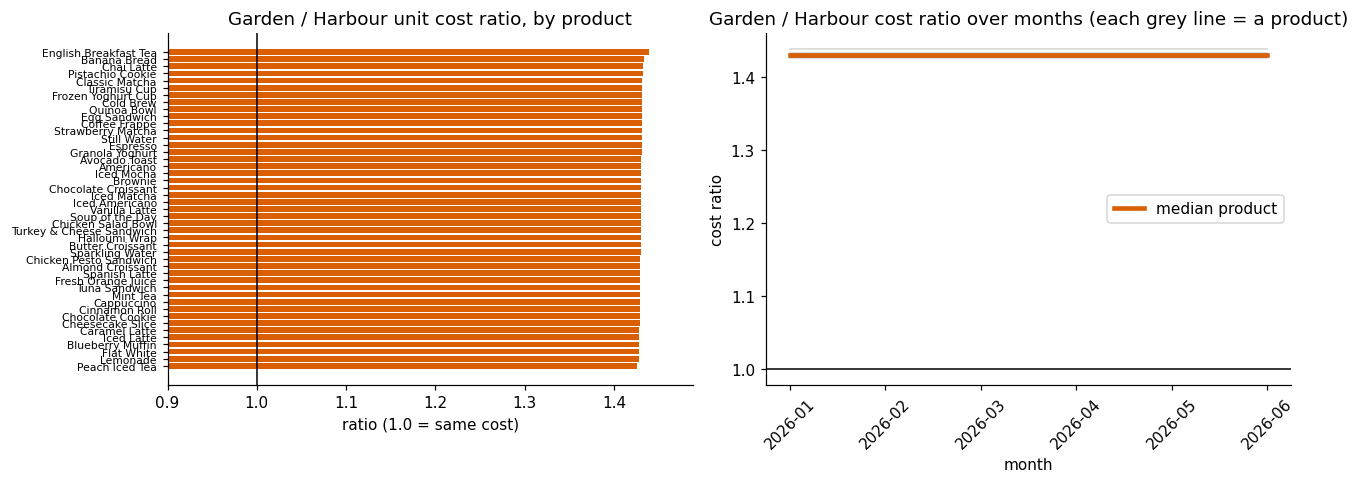

In [7]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
s=cmp.sort_values('cost G/H')
ax[0].barh(s.index,s['cost G/H'],color=COL['Garden']); ax[0].axvline(1,color='k',lw=1)
ax[0].set_xlim(min(0.9,s['cost G/H'].min()-0.02),s['cost G/H'].max()+0.05)
ax[0].set_title('Garden / Harbour unit cost ratio, by product'); ax[0].set_xlabel('ratio (1.0 = same cost)'); ax[0].tick_params(axis='y',labelsize=7)
piv=r.unstack('Month')
for p in piv.index: ax[1].plot(piv.columns,piv.loc[p],color='grey',alpha=.35,lw=1)
ax[1].plot(piv.columns,piv.median(),color=COL['Garden'],lw=3,label='median product')
ax[1].axhline(1,color='k',lw=1); ax[1].set_title('Garden / Harbour cost ratio over months (each grey line = a product)')
ax[1].set_xlabel('month'); ax[1].set_ylabel('cost ratio'); ax[1].tick_params(axis='x',rotation=45); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG+'01_cost_ratio.png'); plt.show()

## 3. Gross margin by branch and by category
Gross margin % = sum of line gross profit / sum of line revenue.

In [8]:
def gm(g): return pd.Series({'revenue':g.rev.sum(),'gross_profit':g.gp.sum(),'gm_%':g.gp.sum()/g.rev.sum()*100,'lines':len(g)})
bb=df.groupby('Branch').apply(gm,include_groups=False); print(bb.round(2)); print()
bc=df.groupby(['Category','Branch']).apply(gm,include_groups=False)['gm_%'].unstack().round(2)
bc['Garden - Harbour (pp)']=bc.Garden-bc.Harbour; bc['Garden - Uptown (pp)']=bc.Garden-bc.Uptown
print(bc.sort_values('Garden - Harbour (pp)').to_string())
print('\nBranch product mix (share of revenue by category, %):')
print((df.groupby(['Branch','Category']).rev.sum().unstack(0).pipe(lambda x:x/x.sum()*100)).round(1).to_string())

           revenue  gross_profit   gm_%    lines
Branch                                          
Garden    99530.55      46696.16  46.92  16869.0
Harbour  150099.05      97503.46  64.96  24586.0
Uptown    55554.11      34794.66  62.63   9590.0

Branch        Garden  Harbour  Uptown  Garden - Harbour (pp)  Garden - Uptown (pp)
Category                                                                          
Sandwiches     34.20    56.22   54.13                 -22.02                -19.93
Desserts       35.64    56.49   55.01                 -20.85                -19.37
Meals          38.33    58.96   56.80                 -20.63                -18.47
Breakfast      40.36    60.26   58.13                 -19.90                -17.77
Bakery         48.73    65.74   64.13                 -17.01                -15.40
Matcha & Tea   49.78    66.67   64.93                 -16.89                -15.15
Cold Drinks    53.30    68.53   66.98                 -15.23                -13.68
Hot Cof

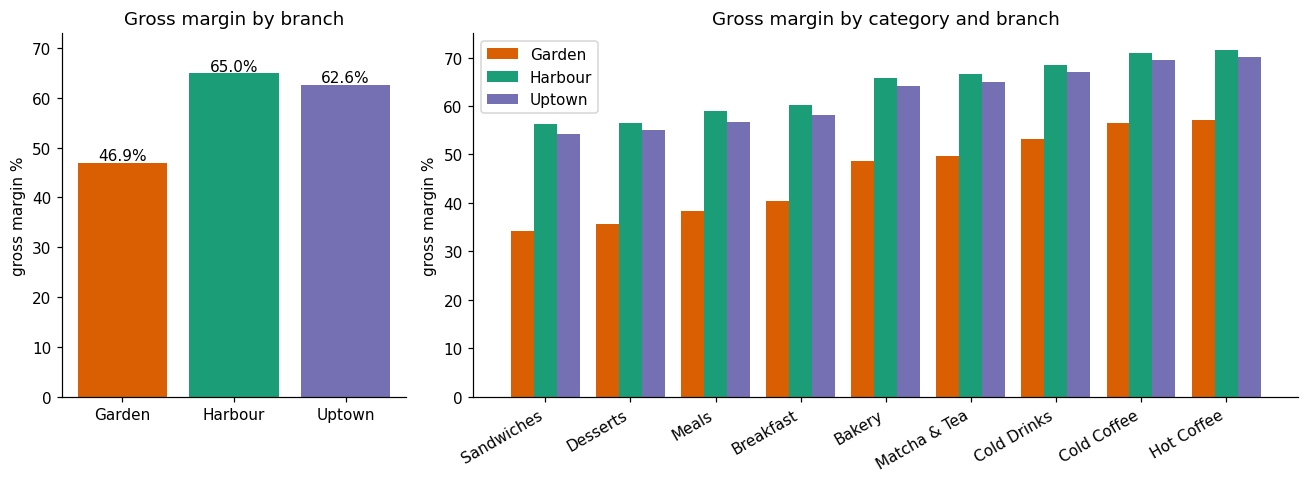

In [9]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5),gridspec_kw={'width_ratios':[1,2.4]})
ax[0].bar(bb.index,bb['gm_%'],color=[COL[b] for b in bb.index])
for i,v in enumerate(bb['gm_%']): ax[0].text(i,v+.5,f'{v:.1f}%',ha='center')
ax[0].set_ylim(0,bb['gm_%'].max()+8); ax[0].set_title('Gross margin by branch'); ax[0].set_ylabel('gross margin %')
x=np.arange(len(bc)); bw=.27
bco=bc.sort_values('Garden')
for i,b in enumerate(['Garden','Harbour','Uptown']): ax[1].bar(np.arange(len(bco))+(i-1)*bw,bco[b],bw,label=b,color=COL[b])
ax[1].set_xticks(range(len(bco))); ax[1].set_xticklabels(bco.index,rotation=30,ha='right'); ax[1].set_ylabel('gross margin %')
ax[1].set_title('Gross margin by category and branch'); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG+'02_margin_branch_category.png'); plt.show()

## 4. Alternative explanations
Idea: if Garden's gap were caused by a different **mix** (more perishable food, more takeaway, more rush-hour sales), the Garden/Harbour cost and price ratios would change by segment. If the gap is a branch-wide pricing/cost policy, the ratios should be flat across segments.

Method: for every Garden line, divide its unit cost (and list price) by Harbour's average for the **same product in the same month**. Then average those ratios per segment (cost-weighted by Garden revenue is not needed since each line is a ratio of the same item). Perishable food = Bakery, Desserts, Sandwiches, Breakfast, Meals; Coffee = Hot Coffee + Cold Coffee; other drinks = Matcha & Tea, Cold Drinks.

In [10]:
ref=df[df.Branch=='Harbour'].groupby(['Product','Month']).agg(h_cost=('cost','mean'),h_price=('price','mean')).reset_index()
g=df[df.Branch=='Garden'].merge(ref,on=['Product','Month'],how='left')
print('Garden lines without a Harbour reference:',g.h_cost.isna().sum())
g['cost_ratio']=g.cost/g.h_cost; g['price_ratio']=g.price/g.h_price
g['group']=g.Category.map({'Hot Coffee':'Coffee','Cold Coffee':'Coffee','Bakery':'Perishable food','Desserts':'Perishable food','Sandwiches':'Perishable food','Breakfast':'Perishable food','Meals':'Perishable food'}).fillna('Other drinks')
g['daypart']=pd.cut(g.Hour,[-1,10,13,16,20,24],labels=['<=10h','11-13h','14-16h','17-20h','21-23h'])
def seg(col):
    t=g.groupby(col,observed=True).agg(lines=('cost','size'),cost_ratio=('cost_ratio','mean'),cost_ratio_sd=('cost_ratio','std'),price_ratio=('price_ratio','mean'))
    return t.round(3)
for c in ['group','Category','otype','Hour']:
    print('--- Garden vs Harbour ratio by',c); print(seg(c).to_string()); print()

Garden lines without a Harbour reference: 0
--- Garden vs Harbour ratio by group
                 lines  cost_ratio  cost_ratio_sd  price_ratio
group                                                         
Coffee            4954       1.429          0.001        0.952
Other drinks      4178       1.430          0.002        0.952
Perishable food   7737       1.430          0.001        0.952

--- Garden vs Harbour ratio by Category
              lines  cost_ratio  cost_ratio_sd  price_ratio
Category                                                   
Bakery         3532       1.430          0.002        0.953
Breakfast       783       1.431          0.000        0.952
Cold Coffee    2335       1.430          0.001        0.952
Cold Drinks    1711       1.429          0.002        0.952
Desserts       1851       1.430          0.001        0.952
Hot Coffee     2619       1.429          0.001        0.952
Matcha & Tea   2467       1.431          0.002        0.953
Meals           469    

In [11]:
# Margin gap (pp) Garden vs Harbour by segment, for all three segmentations
dh=df[df.Branch.isin(['Garden','Harbour'])].copy()
dh['group']=dh.Category.map({'Hot Coffee':'Coffee','Cold Coffee':'Coffee','Bakery':'Perishable food','Desserts':'Perishable food','Sandwiches':'Perishable food','Breakfast':'Perishable food','Meals':'Perishable food'}).fillna('Other drinks')
for c in ['group','otype','Hour']:
    t=dh.groupby([c,'Branch']).apply(lambda x:x.gp.sum()/x.rev.sum()*100,include_groups=False).unstack()
    t['gap_pp']=t.Garden-t.Harbour; print(t.round(2).to_string()); print()
# mix check: Garden margin if it kept its own mix but used Harbour's per-category margin
mixG=df[df.Branch=='Garden'].groupby('Category').rev.sum(); mixG=mixG/mixG.sum()
hm=df[df.Branch=='Harbour'].groupby('Category').apply(lambda x:x.gp.sum()/x.rev.sum(),include_groups=False)
print('Garden margin at Harbour category margins and Garden mix: %.2f%%'%((mixG*hm).sum()*100))
print('Actual Harbour margin: %.2f%% | Actual Garden margin: %.2f%%'%(bb.loc['Harbour','gm_%'],bb.loc['Garden','gm_%']))

Branch           Garden  Harbour  gap_pp
group                                   
Coffee            56.79    71.19  -14.40
Other drinks      50.84    67.22  -16.38
Perishable food   40.13    60.35  -20.22

Branch    Garden  Harbour  gap_pp
otype                            
Dine-in    46.84    64.99  -18.16
Takeaway   47.03    64.91  -17.88

Branch  Garden  Harbour  gap_pp
Hour                           
7        48.06    65.75  -17.69
8        48.19    65.29  -17.10
9        47.69    65.71  -18.02
10       47.54    65.53  -17.99
11       46.76    65.04  -18.28
12       46.61    65.36  -18.75
13       46.60    64.87  -18.27
14       47.15    64.87  -17.72
15       46.71    64.86  -18.16
16       46.81    64.74  -17.93
17       46.98    64.49  -17.50
18       46.78    65.10  -18.32
19       46.86    64.84  -17.98
20       47.00    64.87  -17.87
21       46.31    64.89  -18.58
22       46.91    64.63  -17.71
23       46.90    64.92  -18.02

Garden margin at Harbour category margins and Ga

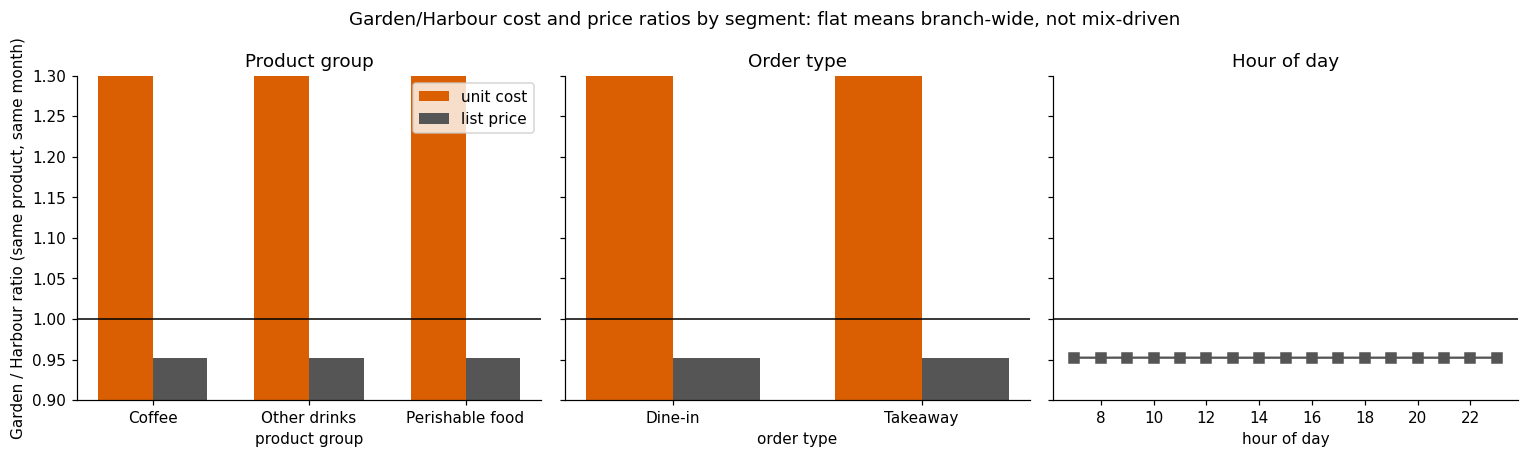

In [12]:
fig,ax=plt.subplots(1,3,figsize=(14,4.2),sharey=True)
for a,(c,t) in zip(ax,[('group','Product group'),('otype','Order type'),('Hour','Hour of day')]):
    s=g.groupby(c,observed=True)[['cost_ratio','price_ratio']].mean()
    if c=='Hour':
        a.plot(s.index,s.cost_ratio,'o-',color=COL['Garden'],label='unit cost'); a.plot(s.index,s.price_ratio,'s-',color='#555',label='list price')
    else:
        w=.35; xx=np.arange(len(s)); a.bar(xx-w/2,s.cost_ratio,w,color=COL['Garden'],label='unit cost'); a.bar(xx+w/2,s.price_ratio,w,color='#555',label='list price'); a.set_xticks(xx); a.set_xticklabels(s.index)
    a.axhline(1,color='k',lw=1); a.set_title(t); a.set_xlabel(t.lower())
ax[0].set_ylabel('Garden / Harbour ratio (same product, same month)'); ax[0].set_ylim(0.9,1.3); ax[0].legend()
fig.suptitle('Garden/Harbour cost and price ratios by segment: flat means branch-wide, not mix-driven')
plt.tight_layout(); plt.savefig(FIG+'03_alternative_explanations.png'); plt.show()

## 5. Counterfactual profit for Garden
**Assumptions**
1. Volumes, product mix, discounts, order types and timing at Garden stay exactly as observed (no demand response to price changes; price elasticity is not estimated, so scenario B is an upper bound if higher prices were the cause of lost volume, or a plain mechanical estimate otherwise).
2. 'Harbour costs' = Harbour's average unit cost for the same product in the same month. 'Harbour prices' = Harbour's average list price for the same product in the same month. Garden's own discount rate on each line is kept.
3. Cost scenario: new gross profit = revenue - qty * Harbour unit cost; revenue unchanged.
4. Price scenario: new revenue = qty * Harbour list price * (1 - Garden discount); Garden cost unchanged.
5. Gross profit only: no staff, rent or overhead effects. Data are the transactions given (after de-duplication); the period is the data period, not annualised.
6. A negative number would mean Garden is already better than Harbour for that line.

In [13]:
g['new_cost_total']=g.qty*g.h_cost
g['new_rev_price']=g.qty*g.h_price*(1-g['Discount Rate'])
act_gp=g.gp.sum(); act_rev=g.rev.sum()
extraA=(g.qty*g.cost-g.new_cost_total).sum()
extraB=(g.new_rev_price-g.rev).sum()
print('Garden actual revenue: %.0f | gross profit: %.0f | margin %.2f%%'%(act_rev,act_gp,act_gp/act_rev*100))
print('\nA) Harbour costs:  extra gross profit = %.0f  (+%.1f%% of GP) | new margin %.2f%%'%(extraA,extraA/act_gp*100,(act_gp+extraA)/act_rev*100))
print('B) Harbour prices: extra gross profit = %.0f  (+%.1f%% of GP) | new margin %.2f%%'%(extraB,extraB/act_gp*100,(act_gp+extraB)/(act_rev+extraB)*100))
print('C) Both:           extra gross profit = %.0f'%(extraA+extraB))
months=g.Month.nunique(); print('\nPeriod covers %d months -> A about %.0f/month, B about %.0f/month'%(months,extraA/months,extraB/months))
# which products / categories drive it
t=g.assign(A=g.qty*g.cost-g.new_cost_total,B=g.new_rev_price-g.rev).groupby('Category')[['A','B']].sum().round(0)
t['A_share_%']=(t.A/t.A.sum()*100).round(1); print(); print(t.sort_values('A',ascending=False).to_string())


Garden actual revenue: 99531 | gross profit: 46696 | margin 46.92%

A) Harbour costs:  extra gross profit = 15888  (+34.0% of GP) | new margin 62.88%
B) Harbour prices: extra gross profit = 4974  (+10.7% of GP) | new margin 49.44%
C) Both:           extra gross profit = 20862

Period covers 6 months -> A about 2648/month, B about 829/month

                   A      B  A_share_%
Category                              
Matcha & Tea  2449.0  803.0       15.4
Bakery        2313.0  748.0       14.6
Desserts      2289.0  595.0       14.4
Sandwiches    2272.0  575.0       14.3
Cold Coffee   1692.0  650.0       10.7
Hot Coffee    1633.0  634.0       10.3
Breakfast     1278.0  356.0        8.0
Cold Drinks    982.0  351.0        6.2
Meals          978.0  263.0        6.2


In [14]:
# sensitivity of B: GP under Harbour prices if a share of Garden volume were lost
gp_new=(g.new_rev_price-g.qty*g.cost).sum()
for loss in [0,.05,.10,.15]:
    print('B with %2d%% volume loss: extra GP = %6.0f'%(loss*100,(1-loss)*gp_new-act_gp))

B with  0% volume loss: extra GP =   4974
B with  5% volume loss: extra GP =   2391
B with 10% volume loss: extra GP =   -193
B with 15% volume loss: extra GP =  -2776


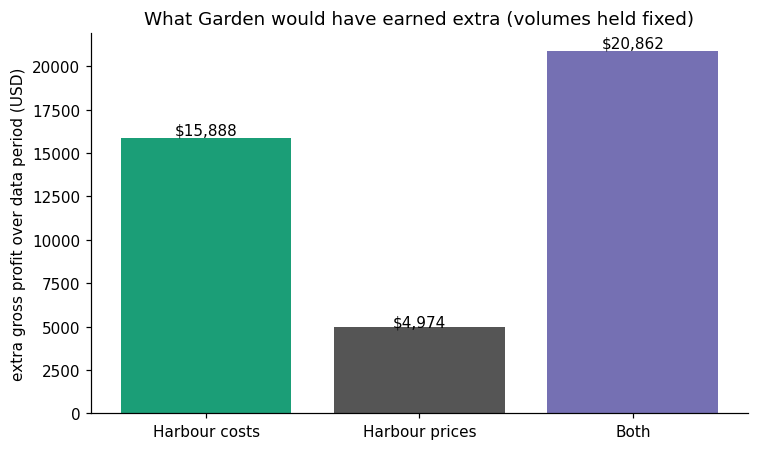

In [15]:
fig,ax=plt.subplots(figsize=(7,4.2))
vals=[extraA,extraB,extraA+extraB]; lab=['Harbour costs','Harbour prices','Both']
ax.bar(lab,vals,color=[COL['Harbour'],'#555',COL['Uptown']])
for i,v in enumerate(vals): ax.text(i,v*1.01,f'${v:,.0f}',ha='center')
ax.set_ylabel('extra gross profit over data period (USD)'); ax.set_title('What Garden would have earned extra (volumes held fixed)')
plt.tight_layout(); plt.savefig(FIG+'04_extra_profit.png'); plt.show()

## 6. Summary
See the printed results above. Key numbers are in the cells for sections 2, 3, 4 and 5; the written summary is given in the chat reply.